# Baseline 2 - Vision Transformer Backbone

# Load & Extract Dataset From Drive

In [1]:
from google.colab import drive
drive.mount('/content/drive')

# 1. Copy the .7z file to the local Colab /content/ directory
!cp /content/drive/MyDrive/COS30082/DPD_Small.7z /content/

# 2. Extract the .7z archive using the 7z utility
# 'x' extracts with full paths, '-o' specifies the output directory (no space after -o)
!7z x /content/DPD_Small.7z -o/content/data/

Mounted at /content/drive

7-Zip 23.01 (x64) : Copyright (c) 1999-2023 Igor Pavlov : 2023-06-20
 64-bit locale=en_US.UTF-8 Threads:2 OPEN_MAX:1048576

Scanning the drive for archives:
  0M Scan /content/                   1 file, 3399045528 bytes (3242 MiB)

Extracting archive: /content/DPD_Small.7z
--
Path = /content/DPD_Small.7z
Type = 7z
Physical Size = 3399045528
Headers Size = 107901
Method = LZMA2:25
Solid = +
Blocks = 1

  0%      0% 1        1% 1        2% 1        3% 1        4% 1        5% 1        6% 1        6% 1 - DPD_Small_dataset/APPD_apple_healthy_138.jpg                                                       7% 409 - DPD_Small_dataset/CC_coffee_rust_533.jpg                                

# Imports

In [2]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.models as models
from torch.cuda.amp import GradScaler, autocast
from torch.optim import AdamW
from torch.optim.lr_scheduler import CosineAnnealingLR
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.transforms import InterpolationMode
from tqdm.auto import tqdm
import os
import gradio as gr
import pandas as pd
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

# Data Check Function

In [3]:
def run_data_checks(data_dir, train_csv, test_seen_csv, test_unseen_csv, sample_check_limit=500):
    """
    Performs comprehensive dataset health checks across CSV annotations and image files.
    """
    print("=" * 70)
    print("                      DATA INTEGRITY CHECK REPORT                      ")
    print("=" * 70)

    csv_files = {
        'Train': train_csv,
        'Test Seen': test_seen_csv,
        'Test Unseen': test_unseen_csv
    }

    dfs = {}
    all_passed = True

    # 1. Load CSVs and check missing values
    for name, path in csv_files.items():
        if not os.path.exists(path):
            print(f"[ERROR] {name} CSV not found at: {path}")
            all_passed = False
            continue

        df = pd.read_csv(path, header=None)
        dfs[name] = df
        null_count = df.isnull().sum().sum()
        print(f"[CHECK 1] {name:<12} | Rows: {len(df):<5} | Columns: {df.shape[1]} | Missing/Null Values: {null_count}")
        if null_count > 0:
            print(f"   [WARNING] Found missing values in {name} CSV!")
            all_passed = False

    if len(dfs) < 3:
        print("[STOP] Missing required CSV files. Please verify paths.")
        return False

    print("-" * 70)

    # 2. Category & Class Distribution Analysis
    train_df = dfs['Train']
    seen_df = dfs['Test Seen']
    unseen_df = dfs['Test Unseen']

    train_crops = train_df[1].nunique()
    train_diseases = train_df[2].nunique()
    train_comps = set(train_df[3].unique())
    unseen_comps = set(unseen_df[3].unique())

    print(f"[CHECK 2] Category Class Statistics:")
    print(f"   - Unique Train Crops (Col 1): {train_crops} (Expected: ~55)")
    print(f"   - Unique Train Diseases (Col 2): {train_diseases} (Expected: ~175)")
    print(f"   - Unique Train Compositions (Col 3): {len(train_comps)}")
    print(f"   - Unique Unseen Compositions (Col 3): {len(unseen_comps)}")

    # 3. Verify Zero-Shot Split Alignment
    overlap = train_comps.intersection(unseen_comps)
    if len(overlap) == 0:
        print(f"[CHECK 3] Zero-Shot Split Verification: PASSED (0 unseen compositions in train set)")
    else:
        print(f"[CHECK 3] Zero-Shot Split Verification: FAILED! Found overlapping compositions: {overlap}")
        all_passed = False

    print("-" * 70)

    # 4. Image Existence & Corrupt File Check (Sampled or Full)
    if not os.path.exists(data_dir):
        print(f"[WARNING] Image directory '{data_dir}' not found. Skipping physical file check.")
        print("   Please mount Drive or unzip dataset images to enable file verification.")
        return all_passed

    print(f"[CHECK 4] Verifying Image Files in '{data_dir}'...")
    missing_files = 0
    corrupt_files = 0
    image_modes = {}
    resolutions = []

    # Sample or full check
    sample_df = train_df.sample(n=min(sample_check_limit, len(train_df)), random_state=42)

    for idx, row in sample_df.iterrows():
        img_name = str(row.iloc[0])
        img_path = os.path.join(data_dir, img_name)

        if not os.path.exists(img_path):
            missing_files += 1
            continue

        try:
            with Image.open(img_path) as img:
                img.verify()  # Check for corrupt bytes
            # Re-open for dimension inspection after verify()
            with Image.open(img_path) as img:
                mode = img.mode
                image_modes[mode] = image_modes.get(mode, 0) + 1
                resolutions.append(img.size)
        except Exception as e:
            corrupt_files += 1

    print(f"   - Sampled Files Checked: {len(sample_df)}")
    print(f"   - Missing Files: {missing_files}")
    print(f"   - Corrupt Files: {corrupt_files}")
    print(f"   - Color Channels Detected: {image_modes}")
    if resolutions:
        widths, heights = zip(*resolutions)
        print(f"   - Resolution Range: Width {min(widths)}-{max(widths)}px | Height {min(heights)}-{max(heights)}px")

    if missing_files > 0 or corrupt_files > 0:
        all_passed = False
        print("   [WARNING] File errors detected! Ensure image directory matches CSV filenames.")
    else:
        print("[CHECK 4] Image File Integrity: PASSED")

    print("=" * 70)
    if all_passed:
        print("STATUS: ALL DATA CHECKS PASSED SUCCESSFULLY!")
    else:
        print("STATUS: CHECKS COMPLETED WITH WARNINGS/ERRORS. SEE DETAILS ABOVE.")
    print("=" * 70)
    return all_passed

# ViT Architecture Setup

In [4]:
# 2. Multi-Task Vision Transformer Architecture
class MultiTaskViT(nn.Module):
    def __init__(self):
        super().__init__()
        # Load pre-trained ViT-B/16
        self.backbone = models.vit_b_16(weights=models.ViT_B_16_Weights.DEFAULT)

        # Extract the input feature dimension from the default head (768 for ViT-B)
        in_features = self.backbone.heads.head.in_features

        # Strip the default ImageNet classification head
        self.backbone.heads = nn.Identity()

        # Define the three parallel classification heads
        self.head_crop = nn.Linear(in_features, 55)
        self.head_disease = nn.Linear(in_features, 175)
        self.head_comp = nn.Linear(in_features, 333)

    def forward(self, x):
        # Extract sequence representations [Batch, 768]
        features = self.backbone(x)

        # Pass features through all three heads
        out_crop = self.head_crop(features)
        out_disease = self.head_disease(features)
        out_comp = self.head_comp(features)

        return out_crop, out_disease, out_comp

# Dataset Setup

In [5]:
class DPDSmallDataset(Dataset):
    """
    Custom PyTorch Dataset for DPD-Small.

    CSV Column Index Mapping:
    0: Image filename
    1: Crop category ID (int, 0-54)
    2: Disease category ID (int, 0-174)
    3: Composition category ID (int, 0-332)
    4: Crop category name (str)
    5: Disease category name (str)
    6: Composition category name (str)
    """
    def __init__(self, csv_file, img_dir, transform=None):
        self.data_frame = pd.read_csv(csv_file, header=None)
        self.img_dir = img_dir
        self.transform = transform

    def __len__(self):
        return len(self.data_frame)

    def __getitem__(self, idx):
        if torch.is_tensor(idx):
            idx = idx.tolist()

        row = self.data_frame.iloc[idx]

        img_name = str(row.iloc[0])
        img_path = os.path.join(self.img_dir, img_name)

        image = Image.open(img_path).convert('RGB')

        crop_label = torch.tensor(int(row.iloc[1]), dtype=torch.long)
        disease_label = torch.tensor(int(row.iloc[2]), dtype=torch.long)
        comp_label = torch.tensor(int(row.iloc[3]), dtype=torch.long)

        crop_name = str(row.iloc[4])
        disease_name = str(row.iloc[5])
        comp_name = str(row.iloc[6])

        if self.transform:
            image = self.transform(image)

        return {
            'image': image,
            'crop_label': crop_label,
            'disease_label': disease_label,
            'comp_label': comp_label,
            'crop_name': crop_name,
            'disease_name': disease_name,
            'comp_name': comp_name,
            'img_name': img_name
        }

# Multi-backbone Baseline Setup

In [6]:
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

# --- Baseline 1: ResNet Pipeline (Bilinear Interpolation) ---
resnet_train_transforms = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.8, 1.0), interpolation=InterpolationMode.BILINEAR),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD)
])

resnet_eval_transforms = transforms.Compose([
    transforms.Resize((224, 224), interpolation=InterpolationMode.BILINEAR),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD)
])

# --- Baseline 2: ViT / DINO Pipeline (Bicubic Interpolation) ---
vit_dino_train_transforms = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.8, 1.0), interpolation=InterpolationMode.BICUBIC),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.3),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD)
])

vit_dino_eval_transforms = transforms.Compose([
    transforms.Resize((224, 224), interpolation=InterpolationMode.BICUBIC),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD)
])

# Data Loader Function

In [7]:
def get_dpd_dataloaders(
    data_dir,
    train_csv,
    test_seen_csv,
    test_unseen_csv,
    model_type='resnet',
    batch_size=32,
    num_workers=2
):
    """
    Returns train, test_seen, and test_unseen PyTorch DataLoaders.
    """
    model_type_clean = model_type.lower()

    if model_type_clean == 'resnet':
        train_tf = resnet_train_transforms
        eval_tf = resnet_eval_transforms
    elif model_type_clean in ['vit', 'dino', 'vit_dino']:
        train_tf = vit_dino_train_transforms
        eval_tf = vit_dino_eval_transforms
    else:
        raise ValueError(f"Unsupported model_type: '{model_type}'. Choose 'resnet' or 'vit_dino'.")

    train_dataset = DPDSmallDataset(train_csv, data_dir, transform=train_tf)
    test_seen_dataset = DPDSmallDataset(test_seen_csv, data_dir, transform=eval_tf)
    test_unseen_dataset = DPDSmallDataset(test_unseen_csv, data_dir, transform=eval_tf)

    train_loader = DataLoader(
        train_dataset, batch_size=batch_size, shuffle=True, num_workers=num_workers, pin_memory=True
    )
    test_seen_loader = DataLoader(
        test_seen_dataset, batch_size=batch_size, shuffle=False, num_workers=num_workers, pin_memory=True
    )
    test_unseen_loader = DataLoader(
        test_unseen_dataset, batch_size=batch_size, shuffle=False, num_workers=num_workers, pin_memory=True
    )

    return train_loader, test_seen_loader, test_unseen_loader

# Normalization & Augmentation Functions

In [8]:
def denormalize(tensor):
    """Reverses ImageNet normalization on a PyTorch tensor (3, H, W)."""
    mean = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
    std = torch.tensor(IMAGENET_STD).view(3, 1, 1)
    tensor_denorm = tensor * std + mean
    tensor_denorm = torch.clamp(tensor_denorm, 0.0, 1.0)
    return tensor_denorm.permute(1, 2, 0).cpu().numpy()

def visualize_augmentations(img_path, num_samples=3, save_fig_path=None):
    """Plots side-by-side original image and augmentations for ResNet vs ViT/DINO."""
    if not os.path.exists(img_path):
        raise FileNotFoundError(f"Image file not found at: {img_path}")

    raw_img = Image.open(img_path).convert('RGB')

    fig, axes = plt.subplots(2, num_samples + 1, figsize=(3 * (num_samples + 1), 6))
    fig.suptitle(f"Data Augmentations Comparison\nSource Image: {os.path.basename(img_path)}", fontsize=14, fontweight='bold')

    axes[0, 0].imshow(raw_img)
    axes[0, 0].set_title("Original Image", fontweight='bold')
    axes[0, 0].axis('off')

    axes[1, 0].imshow(raw_img)
    axes[1, 0].set_title("Original Image", fontweight='bold')
    axes[1, 0].axis('off')

    for i in range(num_samples):
        aug_tensor = resnet_train_transforms(raw_img)
        axes[0, i + 1].imshow(denormalize(aug_tensor))
        axes[0, i + 1].set_title(f"ResNet Aug {i+1}")
        axes[0, i + 1].axis('off')

    for i in range(num_samples):
        aug_tensor = vit_dino_train_transforms(raw_img)
        axes[1, i + 1].imshow(denormalize(aug_tensor))
        axes[1, i + 1].set_title(f"ViT/DINO Aug {i+1}")
        axes[1, i + 1].axis('off')

    plt.tight_layout()
    if save_fig_path:
        plt.savefig(save_fig_path, bbox_inches='tight', dpi=300)
    plt.show()

# Data Integrity Checking

In [9]:
# --- Define Dataset Paths ---
IMAGE_DIR = "/content/data/DPD_Small_dataset"
TRAIN_CSV = "/content/data/DPD_Small_train.csv"
TEST_SEEN_CSV = "/content/data/DPD_Small_test_seen.csv"
TEST_UNSEEN_CSV = "/content/data/DPD_Small_test_unseen.csv"

# --- Step 1: Run Quick Data Checking Suite (Reduced sample limit for speed) ---
check_passed = run_data_checks(
    data_dir=IMAGE_DIR,
    train_csv=TRAIN_CSV,
    test_seen_csv=TEST_SEEN_CSV,
    test_unseen_csv=TEST_UNSEEN_CSV,
    sample_check_limit=5
)

# --- Step 2: Initialize & Verify Batch Shapes ---
if os.path.exists(TRAIN_CSV) and os.path.exists(IMAGE_DIR):
    train_loader, seen_loader, unseen_loader = get_dpd_dataloaders(
        data_dir=IMAGE_DIR,
        train_csv=TRAIN_CSV,
        test_seen_csv=TEST_SEEN_CSV,
        test_unseen_csv=TEST_UNSEEN_CSV,
        model_type="vit",
        batch_size=32
    )
    batch = next(iter(train_loader))
    print("\nBatch Image Tensor Shape:", batch["image"].shape)        # [32, 3, 224, 224]
    print("Batch Crop Target Tensor Shape:", batch["crop_label"].shape)   # [32]
    print("Batch Disease Target Tensor Shape:", batch["disease_label"].shape) # [32]
else:
    print("\nNote: Ensure CSV files and image directory are available to run full batch tests.")

                      DATA INTEGRITY CHECK REPORT                      
[CHECK 1] Train        | Rows: 8000  | Columns: 7 | Missing/Null Values: 0
[CHECK 1] Test Seen    | Rows: 2000  | Columns: 7 | Missing/Null Values: 0
[CHECK 1] Test Unseen  | Rows: 1448  | Columns: 7 | Missing/Null Values: 0
----------------------------------------------------------------------
[CHECK 2] Category Class Statistics:
   - Unique Train Crops (Col 1): 55 (Expected: ~55)
   - Unique Train Diseases (Col 2): 175 (Expected: ~175)
   - Unique Train Compositions (Col 3): 323
   - Unique Unseen Compositions (Col 3): 10
[CHECK 3] Zero-Shot Split Verification: PASSED (0 unseen compositions in train set)
----------------------------------------------------------------------
[CHECK 4] Verifying Image Files in '/content/data/DPD_Small_dataset'...
   - Sampled Files Checked: 5
   - Missing Files: 0
   - Corrupt Files: 0
   - Color Channels Detected: {'RGB': 5}
   - Resolution Range: Width 400-4000px | Height 400-225

# Augmentation Visualization

Augmentation visualization saved to: augmentation_visualization.png


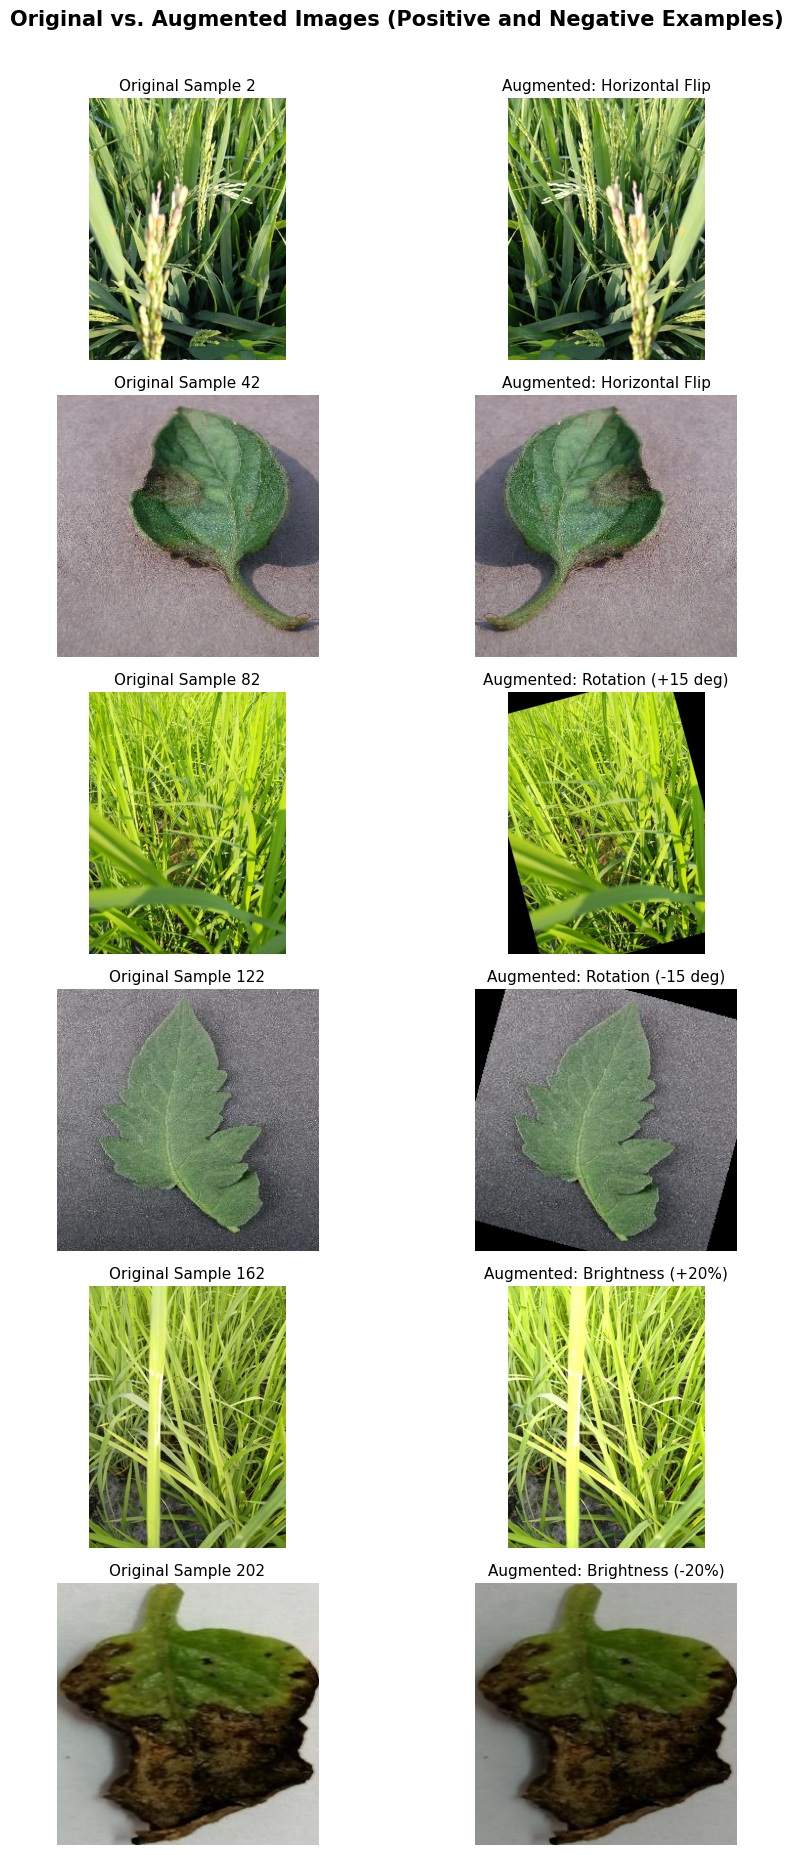

In [10]:
from PIL import ImageEnhance

def visualize_augmentation_examples(
    train_csv,
    image_dir,
    sample_indices=(1, 41, 81, 121, 161, 201),
    save_fig_path=None
):
    """
    Display six original training images beside one clearly labelled augmentation.

    Augmentation examples:
      - Samples 1 and 41: horizontal flip
      - Sample 81: rotation +15 degrees
      - Sample 121: rotation -15 degrees
      - Sample 161: brightness +20%
      - Sample 201: brightness -20%

    sample_indices are zero-based row positions in the training CSV.
    This function is for visualization only; it does not change the
    training augmentation pipelines.
    """
    df = pd.read_csv(train_csv, header=None)

    # Labels and operations are paired by row position.
    operations = [
        ("Horizontal Flip", "flip"),
        ("Horizontal Flip", "flip"),
        ("Rotation (+15 deg)", "rotate_plus"),
        ("Rotation (-15 deg)", "rotate_minus"),
        ("Brightness (+20%)", "bright_plus"),
        ("Brightness (-20%)", "bright_minus"),
    ]

    if len(sample_indices) != len(operations):
        raise ValueError(
            f"Please provide exactly {len(operations)} sample indices "
            "to match the six augmentation examples."
        )

    fig, axes = plt.subplots(
        nrows=len(sample_indices),
        ncols=2,
        figsize=(10, 3.1 * len(sample_indices))
    )
    fig.suptitle(
        "Original vs. Augmented Images (Positive and Negative Examples)",
        fontsize=15,
        fontweight="bold",
        y=0.995
    )

    for row_idx, (sample_idx, operation) in enumerate(zip(sample_indices, operations)):
        if sample_idx < 0 or sample_idx >= len(df):
            raise IndexError(
                f"Sample index {sample_idx} is outside the training CSV "
                f"(valid range: 0 to {len(df) - 1})."
            )

        image_name = str(df.iloc[sample_idx, 0])
        image_path = os.path.join(image_dir, image_name)

        if not os.path.isfile(image_path):
            raise FileNotFoundError(f"Image not found: {image_path}")

        original = Image.open(image_path).convert("RGB")
        operation_name, operation_type = operation

        if operation_type == "flip":
            augmented = original.transpose(Image.Transpose.FLIP_LEFT_RIGHT)
        elif operation_type == "rotate_plus":
            augmented = original.rotate(
                15, resample=Image.Resampling.BICUBIC, expand=False
            )
        elif operation_type == "rotate_minus":
            augmented = original.rotate(
                -15, resample=Image.Resampling.BICUBIC, expand=False
            )
        elif operation_type == "bright_plus":
            augmented = ImageEnhance.Brightness(original).enhance(1.2)
        elif operation_type == "bright_minus":
            augmented = ImageEnhance.Brightness(original).enhance(0.8)
        else:
            raise ValueError(f"Unknown augmentation: {operation_type}")

        axes[row_idx, 0].imshow(original)
        axes[row_idx, 0].set_title(
            f"Original Sample {sample_idx + 1}", fontsize=11
        )
        axes[row_idx, 0].axis("off")

        axes[row_idx, 1].imshow(augmented)
        axes[row_idx, 1].set_title(
            f"Augmented: {operation_name}", fontsize=11
        )
        axes[row_idx, 1].axis("off")

    plt.tight_layout(rect=[0, 0, 1, 0.985])

    if save_fig_path:
        output_dir = os.path.dirname(save_fig_path)
        if output_dir:
            os.makedirs(output_dir, exist_ok=True)
        plt.savefig(save_fig_path, bbox_inches="tight", dpi=300)
        print(f"Augmentation visualization saved to: {save_fig_path}")

    plt.show()


# Run the visualization using the dataset paths defined in the next cell.
# If you run this cell before defining IMAGE_DIR and TRAIN_CSV,
# define those two variables first.
visualize_augmentation_examples(
    train_csv=TRAIN_CSV,
    image_dir=IMAGE_DIR,
    save_fig_path="augmentation_visualization.png"
)


# Data Loading & Hyperparameter Config

In [11]:
# 3. Initialization and Data Loading
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Reusing existing DataLoader pipeline
train_loader, test_seen_loader, test_unseen_loader = get_dpd_dataloaders(
    data_dir='/content/data/DPD_Small_dataset',
    train_csv='/content/data/DPD_Small_train.csv',
    test_seen_csv='/content/data/DPD_Small_test_seen.csv',
    test_unseen_csv='/content/data/DPD_Small_test_unseen.csv',
    model_type='vit_dino'
)

model = MultiTaskViT().to(device)

# Hyperparameters based on the baseline configuration
criterion = nn.CrossEntropyLoss()
optimizer = AdamW(model.parameters(), lr=3e-5, weight_decay=0.05)

epochs = 20
scheduler = CosineAnnealingLR(optimizer, T_max=epochs)
scaler = GradScaler() # For Mixed Precision (AMP)

Downloading: "https://download.pytorch.org/models/vit_b_16-c867db91.pth" to /root/.cache/torch/hub/checkpoints/vit_b_16-c867db91.pth


100%|██████████| 330M/330M [00:03<00:00, 93.0MB/s]
/tmp/ipykernel_654/486107954.py:21: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = GradScaler() # For Mixed Precision (AMP)


# Training ViT Model

In [ ]:
# 4. Multi-Task Training Loop with AMP
best_val_acc = 0.0
save_path = '/content/drive/MyDrive/COS30082/best_multitask_vit.pth'

for epoch in range(epochs):
    model.train()
    running_loss = 0.0

    for batch in train_loader:
        images = batch['image'].to(device)
        crop_labels = batch['crop_label'].to(device)
        disease_labels = batch['disease_label'].to(device)
        comp_labels = batch['comp_label'].to(device)

        optimizer.zero_grad()

        # Mixed Precision Forward Pass
        with autocast():
            pred_crop, pred_disease, pred_comp = model(images)

            loss_crop = criterion(pred_crop, crop_labels)
            loss_disease = criterion(pred_disease, disease_labels)
            loss_comp = criterion(pred_comp, comp_labels)

            # Combine losses
            total_loss = loss_crop + loss_disease + loss_comp

        # Mixed Precision Backward Pass
        scaler.scale(total_loss).backward()
        scaler.step(optimizer)
        scaler.update()

        running_loss += total_loss.item()

    scheduler.step()
    print(f"Epoch [{epoch+1}/{epochs}] | Train Loss: {running_loss/len(train_loader):.4f}")

    # 5. Validation Loop (Example on test_seen_loader)
    model.eval()
    correct_crop, correct_disease, correct_comp = 0, 0, 0
    total = 0

    with torch.no_grad():
        for batch in test_seen_loader:
            images = batch['image'].to(device)
            crop_labels = batch['crop_label'].to(device)
            disease_labels = batch['disease_label'].to(device)
            comp_labels = batch['comp_label'].to(device)

            with autocast():
                pred_crop, pred_disease, pred_comp = model(images)

            _, predicted_crop = torch.max(pred_crop, 1)
            _, predicted_disease = torch.max(pred_disease, 1)
            _, predicted_comp = torch.max(pred_comp, 1)

            total += crop_labels.size(0)
            correct_crop += (predicted_crop == crop_labels).sum().item()
            correct_disease += (predicted_disease == disease_labels).sum().item()
            correct_comp += (predicted_comp == comp_labels).sum().item()

    acc_crop = 100 * correct_crop / total
    acc_disease = 100 * correct_disease / total
    acc_comp = 100 * correct_comp / total
    avg_acc = (acc_crop + acc_disease + acc_comp) / 3

    print(f"Val Acc -> Crop: {acc_crop:.2f}% | Disease: {acc_disease:.2f}% | Comp: {acc_comp:.2f}%")

    # Save the best model straight to Drive to prevent disconnect data loss
    if avg_acc > best_val_acc:
        best_val_acc = avg_acc
        torch.save(model.state_dict(), save_path)
        print(f"New best model saved with Average Acc: {best_val_acc:.2f}%")

/tmp/ipykernel_525/646498810.py:18: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():


Epoch [1/20] | Train Loss: 8.2562


/tmp/ipykernel_525/646498810.py:50: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():


Val Acc -> Crop: 78.35% | Disease: 48.50% | Comp: 41.45%
New best model saved with Average Acc: 56.10%
Epoch [2/20] | Train Loss: 4.3579
Val Acc -> Crop: 81.50% | Disease: 58.20% | Comp: 51.90%
New best model saved with Average Acc: 63.87%
Epoch [3/20] | Train Loss: 2.9403
Val Acc -> Crop: 85.15% | Disease: 62.70% | Comp: 58.20%
New best model saved with Average Acc: 68.68%
Epoch [4/20] | Train Loss: 2.1683
Val Acc -> Crop: 86.10% | Disease: 65.10% | Comp: 59.85%
New best model saved with Average Acc: 70.35%
Epoch [5/20] | Train Loss: 1.6843
Val Acc -> Crop: 87.30% | Disease: 65.10% | Comp: 62.50%
New best model saved with Average Acc: 71.63%
Epoch [6/20] | Train Loss: 1.3522
Val Acc -> Crop: 87.55% | Disease: 66.45% | Comp: 64.25%
New best model saved with Average Acc: 72.75%
Epoch [7/20] | Train Loss: 1.0592
Val Acc -> Crop: 88.45% | Disease: 68.45% | Comp: 64.95%
New best model saved with Average Acc: 73.95%
Epoch [8/20] | Train Loss: 0.8645
Val Acc -> Crop: 88.55% | Disease: 68.25%

# Inferences on Unseen Data

In [12]:
# 1. Ensure model is in evaluation mode and loaded with the best weights
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model_path = '/content/drive/MyDrive/COS30082/best_multitask_vit.pth'

# Assuming 'model' is already instantiated in your notebook
model.load_state_dict(torch.load(model_path, map_location=device))
model.to(device)
model.eval()

# 2. Initialize tracking variables
correct_crop, correct_disease, correct_comp = 0, 0, 0
total = 0

print("Evaluating on Unseen Holdout Data...")

# 3. Run the evaluation loop without calculating gradients
with torch.no_grad():
    for batch in test_unseen_loader:
        images = batch['image'].to(device)
        crop_labels = batch['crop_label'].to(device)
        disease_labels = batch['disease_label'].to(device)
        comp_labels = batch['comp_label'].to(device)

        # Use mixed precision for faster inference if supported
        with torch.amp.autocast('cuda'):
            pred_crop, pred_disease, pred_comp = model(images)

        # Get the highest probability predictions
        _, predicted_crop = torch.max(pred_crop, 1)
        _, predicted_disease = torch.max(pred_disease, 1)
        _, predicted_comp = torch.max(pred_comp, 1)

        total += crop_labels.size(0)
        correct_crop += (predicted_crop == crop_labels).sum().item()
        correct_disease += (predicted_disease == disease_labels).sum().item()
        correct_comp += (predicted_comp == comp_labels).sum().item()

# 4. Calculate and print final metrics
acc_crop = 100 * correct_crop / total
acc_disease = 100 * correct_disease / total
acc_comp = 100 * correct_comp / total
avg_acc = (acc_crop + acc_disease + acc_comp) / 3

print("-" * 50)
print(f"FINAL UNSEEN ACCURACY")
print("-" * 50)
print(f"Crop Accuracy:    {acc_crop:.2f}%")
print(f"Disease Accuracy: {acc_disease:.2f}%")
print(f"Composite Acc:    {acc_comp:.2f}%")
print(f"Average Accuracy: {avg_acc:.2f}%")
print("-" * 50)

Evaluating on Unseen Holdout Data...
--------------------------------------------------
FINAL UNSEEN ACCURACY
--------------------------------------------------
Crop Accuracy:    61.88%
Disease Accuracy: 10.57%
Composite Acc:    0.00%
Average Accuracy: 24.15%
--------------------------------------------------


# Gradio Test Inferences

In [13]:
# 1. Setup Device & Load Model Architecture
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# IMPORTANT: Instantiate model architecture

# Load the saved weights
model_path = '/content/drive/MyDrive/COS30082/best_multitask_vit.pth'
model.load_state_dict(torch.load(model_path, map_location=device))
model.to(device)
model.eval()

# 2. Define the ViT Eval Transforms (Bicubic interpolation)
transform = transforms.Compose([
    transforms.Resize((224, 224), interpolation=transforms.InterpolationMode.BICUBIC),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

# 3. Class Mappings (Dynamically loaded)
df = pd.read_csv('/content/data/DPD_Small_train.csv', header=None)
crop_classes = dict(zip(df[1], df[4]))
disease_classes = dict(zip(df[2], df[5]))
comp_classes = dict(zip(df[3], df[6]))

# 4. Inference Function for Top-3
def predict_image(image):
    img_tensor = transform(image).unsqueeze(0).to(device)

    with torch.no_grad():
        with torch.amp.autocast('cuda'):
            pred_crop, pred_disease, pred_comp = model(img_tensor)

        # Convert raw logits to probabilities
        prob_crop = F.softmax(pred_crop, dim=1)[0]
        prob_disease = F.softmax(pred_disease, dim=1)[0]
        prob_comp = F.softmax(pred_comp, dim=1)[0]

        # Get Top 3 probabilities and their indices
        top3_prob_crop, top3_idx_crop = torch.topk(prob_crop, 3)
        top3_prob_disease, top3_idx_disease = torch.topk(prob_disease, 3)
        top3_prob_comp, top3_idx_comp = torch.topk(prob_comp, 3)

    # Build dictionaries mapping {Class Name : Confidence Score} for Gradio
    crop_result = {crop_classes.get(idx.item(), f"Class {idx.item()}"): prob.item()
                   for prob, idx in zip(top3_prob_crop, top3_idx_crop)}

    disease_result = {disease_classes.get(idx.item(), f"Class {idx.item()}"): prob.item()
                      for prob, idx in zip(top3_prob_disease, top3_idx_disease)}

    comp_result = {comp_classes.get(idx.item(), f"Class {idx.item()}"): prob.item()
                   for prob, idx in zip(top3_prob_comp, top3_idx_comp)}

    return crop_result, disease_result, comp_result

# 5. Launch Gradio Interface
demo = gr.Interface(
    fn=predict_image,
    inputs=gr.Image(type="pil", label="Upload Plant Image"),
    outputs=[
        gr.Label(num_top_classes=3, label="Predicted Crop"),
        gr.Label(num_top_classes=3, label="Predicted Disease"),
        gr.Label(num_top_classes=3, label="Predicted Composite (Crop + Disease)")
    ],
    title="Multi-Task ViT: Plant Disease Classifier",
    description="Upload an image to simultaneously predict the top 3 crop types, diseases, and composite classes with confidence scores."
)

demo.launch(share=True, debug=True)

Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://fb2ba0eb85c654efa1.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


Keyboard interruption in main thread... closing server.
Killing tunnel 127.0.0.1:7860 <> https://fb2ba0eb85c654efa1.gradio.live
